# 2026 U.S. Senate Midterm Model: Event Edition

This builds on the starter model. Steps 1 through 7 work the same way they did before. What's new is an **event layer** that reads `Events.xlsx` and sorts each event into one of three channels. The channel decides where the event enters the model.

| Channel | What it changes | Do polls already see it? | Where it enters |
|---|---|---|---|
| Opinion | What voters want (scandal, economy, foreign policy, ad money) | Polls after the event do; polls before it don't | Adjusts the polls that predate the event, plus the prior |
| Access | Who gets a counted ballot (ID or documentation rules, purges, closures, mail ballot rules) | No. Polls measure preference among likely voters | Added to the simulated Election Day margin |
| Maps | District lines | Not relevant | No effect on statewide Senate races. Feeds a House seats module |

Other changes:

* The polls can test an opinion event: same-pollster before and after comparisons update your prior about how much it mattered (Step 3c).
* Event uncertainty is one draw per event per simulation, shared by every state the event touches. It adds correlated error, not independent noise.
* A scenario table and a stress test show how much an access shock of a given size moves Senate control (Step 8).
* A small House module shows what a redrawn map does to seats across national environments (Step 9).
* Cleaning fixes: pollster name variants, one survey entered as several versions, a national poll with sample size 0.

All margins are **Democrat (or credible opposition) minus Republican**, in percentage points.

The tuning cells that were blank in the starter now hold values drawn from published forecaster methods and polling-error research (the earlier placeholders are noted in the comments). They are still choices, not facts. Step 7 includes a battleground table, and Step 8 shows how much each access change moves the result.

## Step 0: Setup

The data files live in `../data` (the repo's `data` folder). Outputs from this notebook go to `../outputs/notebook`, so they don't overwrite the script's results in `../outputs`. The model date is pinned to October 15, 2026 so the numbers match the guides; change `TODAY` to run on a later date.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta, norm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
DATA_DIR = Path("../data")
LEANS_FILE = DATA_DIR / "leans_and_regions.csv"
POLLS_FILE = DATA_DIR / "Midterm_Polls.xlsx"
NATIONAL_FILE = DATA_DIR / "National_Polls.xlsx"
EVENTS_FILE = DATA_DIR / "Events.xlsx"
OUT_DIR = Path("../outputs/notebook")   # a Path, so OUT_DIR / "file.csv" works at the end
OUT_DIR.mkdir(parents=True, exist_ok=True)

ELECTION_DAY = pd.Timestamp("2026-11-03")
TODAY = pd.Timestamp("2026-10-15")   # pinned so runs are reproducible; pd.Timestamp.today().normalize() uses today
N_SIMS = 40_000   # Silver Bulletin and FiftyPlusOne run 40,000; MC error on a 50% probability is about +/-0.25 pts
SEED = 2026

rng = np.random.default_rng(SEED)
print(f"Model date {TODAY:%Y-%m-%d}: {(ELECTION_DAY - TODAY).days} days to the election")

Model date 2026-10-15: 19 days to the election


### The Senate map

Which seats are up in 2026 and which party currently holds each. `HOLDOVER_D` / `HOLDOVER_R` are the seats *not* on the ballot. A 50-50 Senate goes to Republicans via the Vice President's tiebreaking vote, so Democrats need 51.

In [3]:
SEATS_UP = {
    # Republican-held
    "Alabama": "R", "Alaska": "R", "Arkansas": "R", "Florida": "R", "Idaho": "R",
    "Iowa": "R", "Kansas": "R", "Kentucky": "R", "Louisiana": "R", "Maine": "R",
    "Mississippi": "R", "Montana": "R", "Nebraska": "R", "North Carolina": "R",
    "Ohio": "R", "Oklahoma": "R", "South Carolina": "R", "South Dakota": "R",
    "Tennessee": "R", "Texas": "R", "West Virginia": "R", "Wyoming": "R",
    # Democratic-held
    "Colorado": "D", "Delaware": "D", "Georgia": "D", "Illinois": "D",
    "Massachusetts": "D", "Michigan": "D", "Minnesota": "D", "New Hampshire": "D",
    "New Jersey": "D", "New Mexico": "D", "Oregon": "D", "Rhode Island": "D",
    "Virginia": "D",
}
HOLDOVER_D = 34   # seats NOT up in 2026 (Dems + the two Indies who caucus with them)
HOLDOVER_R = 31
D_SEATS_FOR_CONTROL = 51   # 50-50 goes to R via the VP tiebreak

# Races where the "Dem%" column is actually an independent.
# Value = probability that the independent caucuses with Democrats if they win.
INDEPENDENT_CAUCUS_PROB_D = {"Nebraska": 0.7}   # was 0.8. Osborn says he will "caucus with everybody"; report results at 0.5 and 0.9 too

RACES = sorted(SEATS_UP)

# The 13 heavily polled, contested races
BATTLEGROUNDS = ["Alaska", "Georgia", "Iowa", "Kansas", "Maine", "Michigan", "Minnesota", "Nebraska",
                 "New Hampshire", "North Carolina", "Ohio", "South Carolina", "Texas"]
print(f"{len(SEATS_UP)} races; holdovers D {HOLDOVER_D}, R {HOLDOVER_R}; "
      f"D needs {D_SEATS_FOR_CONTROL - HOLDOVER_D} wins for control")

35 races; holdovers D 34, R 31; D needs 17 wins for control


## Step 1: Load and clean the data

Same checks as before, plus pollster names. The same firm shows up under more than one spelling (`Morning consult` vs `Morning Consult`, `St.Pete Polls` vs `St. Pete Pols`). That matters twice: the flooding weight counts polls *per pollster*, and the event check in Step 3c compares polls *from the same pollster*. Typos break both.

In [4]:
# Known typos -> one spelling. Case-only differences are collapsed automatically.
POLLSTER_FIXES = {
    "St.Pete Polls": "St. Pete Polls",
    "St. Pete Pols": "St. Pete Polls",
    "HarrixX/Harris Poll": "HarrisX/Harris Poll",
    "Cygnal Politial": "Cygnal Political",
    "Fabrizio, Lee, & Asspcoates": "Fabrizio, Lee & Associates",
}

In [5]:
def clean_pollster_names(names):
    # Fix known typos, then collapse case-only variants to the best-capitalized spelling
    raw = names.astype(str)
    s = raw.str.strip().str.replace(r"\s+", " ", regex=True).replace(POLLSTER_FIXES)
    key = s.str.lower()
    canon = {k: max(g.unique(), key=lambda v: (sum(ch.isupper() for ch in v), (g == v).sum()))
             for k, g in s.groupby(key)}
    out = key.map(canon)
    for a, b in sorted({(a, b) for a, b in zip(raw, out) if a != b}):
        print(f"  pollster name: '{a}' -> '{b}'")
    return out


def load_leans(path):
    leans = pd.read_csv(path)
    leans = leans[leans["State"] != "Source"].copy()          # drop citation row
    leans["State"] = leans["State"].str.strip()
    leans["PartisanLean"] = pd.to_numeric(leans["PartisanLean"])
    return leans.set_index("State")


def load_polls(path):
    p = pd.read_excel(path, sheet_name="Sheet1")
    p["State"] = p["State"].str.strip()
    p["Pollster"] = clean_pollster_names(p["Pollster"])
    p["Date"] = pd.to_datetime(p["Date"])
    p["LVorRV"] = p["LVorRV"].str.upper().str.strip()
    p["Generic"] = p["Generic"].eq("Yes")
    p["Bigger_Field"] = p["Bigger_Field"].eq("Yes")
    p["Partisan"] = p["Partisan (Pollster or Sponsor)"]
    p["margin"] = p["Dem%"] - p["Rep%"]
    unknown = set(p["State"]) - set(SEATS_UP)
    if unknown:
        print(f"WARNING: polls for states without a race: {unknown}")
    return p


def load_national(path):
    n = pd.read_excel(path, sheet_name="Sheet1")
    n["Pollster"] = clean_pollster_names(n["Pollster"])
    n["Date"] = pd.to_datetime(n["Date"])
    n["net"] = n["Approval"] - n["Disapproval"]
    bad = n["SampleSize"].fillna(0) <= 0
    if bad.any():
        print(f"WARNING: {bad.sum()} national poll(s) with no sample size get zero weight: "
              f"{list(n.loc[bad, 'Pollster'])}")
    return n

In [6]:
print("State polls:")
polls_raw = load_polls(POLLS_FILE)
print("National polls:")
nat = load_national(NATIONAL_FILE)
leans = load_leans(LEANS_FILE)

print(f"\n{len(leans)} states with leans, {len(polls_raw)} state polls, {len(nat)} national polls")
missing_lean = set(SEATS_UP) - set(leans.index)
if missing_lean:
    print(f"WARNING: races with no partisan lean: {missing_lean}")
polls_raw.head()

State polls:
  pollster name: 'Cygnal Politial' -> 'Cygnal Political'
  pollster name: 'Fabrizio, Lee, & Asspcoates' -> 'Fabrizio, Lee & Associates'
  pollster name: 'St. Pete Pols' -> 'St. Pete Polls'
  pollster name: 'St.Pete Polls' -> 'St. Pete Polls'
National polls:
  pollster name: 'HarrixX/Harris Poll' -> 'HarrisX/Harris Poll'
  pollster name: 'Morning consult' -> 'Morning Consult'

51 states with leans, 232 state polls, 37 national polls


,Date,State,Pollster,Dem%,Rep%,SampleSize,LVorRV,Partisan (Pollster or Sponsor),Generic,Bigger_Field,Pollster Rank,Typical Error,Partisan,margin
0,2026-10-15,Texas,ActiVote,52,48,400,LV,NaN,False,False,5,NaN,NaN,4
1,2026-10-15,Iowa,Marist University,48,45,1100,LV,NaN,False,False,9,NaN,NaN,3
2,2026-10-14,Mississippi,Wedgewood Polls,48,52,511,LV,NaN,False,False,5,NaN,NaN,-4
3,2026-10-14,Minnesota,SurveyUSA,45,42,718,LV,NaN,False,True,6,NaN,NaN,3
4,2026-10-14,Florida,MDW Communications,42,48,2351,LV,NaN,False,False,5,NaN,NaN,-6


## Step 2: Weight the polls and build state polling averages

Same weighting as the starter, with one addition:

| Factor | Idea |
|---|---|
| Recency | Older polls decay with a half-life |
| Sample size | Bigger samples count more, with diminishing returns (square root) |
| LV vs RV | Likely-voter polls are closer to the actual electorate |
| Partisan sponsor | Polls paid for by a party get down-weighted *and* shifted |
| Generic ballot | "Generic D vs generic R" isn't the real matchup |
| Bigger field | Full-field polls vs head-to-heads (a debatable assumption!) |
| Pollster quality | Based on VoteHub rank |
| Accuracy | Pollsters with smaller historical error count more |
| Flooding | Stops one prolific pollster from dominating a state |
| **Version (new)** | One survey released as head-to-head, full field, and generic is one sample, not three |

The version fix matters here. Co/Efficient's Nebraska poll of 1,113 people appears three times; without it, that one sample gets triple weight.

### ⚙️ Tuning knobs: poll weighting

In [7]:
RECENCY_HALF_LIFE_DAYS = 14      # was 21. Forecasters shorten decay late in the race (FiftyPlusOne ~5 days in the final two weeks)
REFERENCE_SAMPLE = 800           # sample-size weight = sqrt(n / REFERENCE_SAMPLE); only a scaling constant
RV_WEIGHT = 0.85                 # was 0.8
RV_MARGIN_SHIFT = 1.0            # was -0.5. In 2026, LV results run 1-2 pts MORE Democratic than RV (Silver Bulletin, FiftyPlusOne, YouGov)
PARTISAN_WEIGHT = 0.5
PARTISAN_HOUSE_EFFECT = 3.0      # was 2.0. Published estimates run 2-4 pts; FiveThirtyEight found ~4 for Senate partisan polls since 2002
GENERIC_WEIGHT = 0.3             # was 0.5. A generic question leaves out candidate effects
BIGGER_FIELD_WEIGHT = 1.0        # was 0.8. Evidence favors full-field ballots, so no discount for them
COLLAPSE_POLL_VERSIONS = True    # one survey released several ways counts once

QUALITY_SCORE_MIN = 5
QUALITY_SCORE_MAX = 10
MIN_QUALITY_WEIGHT = 0.4         # was 0.5
UNRANKED_SCORE = 6.5             # was 5 (the Sheet2 rule). VoteHub treats new pollsters as roughly average, not worst
MAE_TO_SD = 1.25
DEFAULT_TYPICAL_ERROR = 5.0      # was 4.0. Senate polls in the final three weeks have missed by ~5 pts on average since 1998

SYSTEMATIC_POLL_ERROR_SD = 4.5   # shared polling miss within a state

In [8]:
def weight_polls(p):
    p = p.copy()
    age = (TODAY - p["Date"]).dt.days.clip(lower=0)
    p["w_recency"] = 0.5 ** (age / RECENCY_HALF_LIFE_DAYS)
    p["w_size"] = np.sqrt(p["SampleSize"] / REFERENCE_SAMPLE)
    p["w_type"] = np.where(p["LVorRV"] == "RV", RV_WEIGHT, 1.0)
    p["w_partisan"] = np.where(p["Partisan"].notna(), PARTISAN_WEIGHT, 1.0)
    p["w_generic"] = np.where(p["Generic"], GENERIC_WEIGHT, 1.0)
    p["w_field"] = np.where(p["Bigger_Field"], BIGGER_FIELD_WEIGHT, 1.0)
    score = p["Pollster Rank"].fillna(UNRANKED_SCORE).clip(QUALITY_SCORE_MIN, QUALITY_SCORE_MAX)
    frac = (score - QUALITY_SCORE_MIN) / (QUALITY_SCORE_MAX - QUALITY_SCORE_MIN)
    p["w_quality"] = MIN_QUALITY_WEIGHT + (1 - MIN_QUALITY_WEIGHT) * frac
    pd_, pr_ = p["Dem%"] / 100, p["Rep%"] / 100
    samp_sd = 100 * np.sqrt((pd_ + pr_ - (pd_ - pr_) ** 2) / p["SampleSize"])
    hist_sd = MAE_TO_SD * p["Typical Error"].fillna(DEFAULT_TYPICAL_ERROR)
    p["poll_error_sd"] = np.maximum(samp_sd, hist_sd)
    p["w_accuracy"] = (MAE_TO_SD * DEFAULT_TYPICAL_ERROR / p["poll_error_sd"]) ** 2

    # NEW: one survey (same state, pollster, date, sample size) released several ways is one sample
    p["survey_id"] = p["Date"].astype(str) + "|" + p["SampleSize"].astype(str)
    if COLLAPSE_POLL_VERSIONS:
        p["w_version"] = 1 / p.groupby(["State", "Pollster", "survey_id"])["Pollster"].transform("count")
        n_by_pollster = p.groupby(["State", "Pollster"])["survey_id"].transform("nunique")
    else:
        p["w_version"] = 1.0
        n_by_pollster = p.groupby(["State", "Pollster"])["Pollster"].transform("count")
    p["w_flood"] = 1 / np.sqrt(n_by_pollster)

    p["weight"] = p[[c for c in p.columns if c.startswith("w_")]].prod(axis=1)

    # Margin adjustments (house effects)
    adj = p["margin"].astype(float).copy()
    adj += np.where(p["LVorRV"] == "RV", RV_MARGIN_SHIFT, 0)
    adj -= np.where(p["Partisan"] == "Republican", -PARTISAN_HOUSE_EFFECT, 0)  # R poll -> nudge D
    adj -= np.where(p["Partisan"].isin(["Democrat", "Independent/Dem"]),
                    PARTISAN_HOUSE_EFFECT, 0)                                  # D poll -> nudge R
    p["house_adj_margin"] = adj
    p["event_adj"] = 0.0          # filled in by the opinion events in Step 4
    p["adj_margin"] = adj
    return p


def polling_averages(p):
    def summarize(g):
        w = g["weight"]
        mean = np.average(g["adj_margin"], weights=w)
        n_eff = w.sum() ** 2 / (w ** 2).sum()                 # Kish effective N
        poll_sd = np.sqrt(np.average(g["poll_error_sd"] ** 2, weights=w))
        sd = np.sqrt(poll_sd ** 2 / n_eff + SYSTEMATIC_POLL_ERROR_SD ** 2)
        return pd.Series({"poll_mean": mean, "poll_sd": sd,
                          "n_polls": len(g), "n_eff": n_eff})
    return p.groupby("State")[["weight", "adj_margin", "poll_error_sd"]].apply(summarize)

In [9]:
polls = weight_polls(polls_raw)

weight_cols = [c for c in polls.columns if c.startswith("w_")]
display(polls.loc[polls["State"] == "Nebraska",
                  ["Pollster", "Date", "margin", "adj_margin"] + weight_cols + ["weight"]]
        .assign(Date=lambda d: d["Date"].dt.date)
        .sort_values("weight", ascending=False).round(3))
polling_averages(polls).round(2)

,Pollster,Date,margin,adj_margin,w_recency,w_size,w_type,w_partisan,w_generic,w_field,w_quality,w_accuracy,w_version,w_flood,weight
50,YouGov,2026-10-06,1,1.0,0.640,1.503,1.0,1.0,1.0,1.0,0.76,1.0,1.000,1.000,0.732
105,GBAO,2026-09-28,1,-2.0,0.431,1.000,1.0,0.5,1.0,1.0,0.76,1.0,1.000,0.707,0.116
120,GBAO,2026-09-25,1,-2.0,0.371,1.000,1.0,0.5,1.0,1.0,0.76,1.0,1.000,0.707,0.100
184,SurveyUSA,2026-09-14,4,4.0,0.215,0.793,1.0,1.0,1.0,1.0,0.52,1.0,1.000,1.000,0.089
71,Co/Efficient,2026-10-02,-3,-3.0,0.525,1.180,1.0,1.0,1.0,1.0,0.40,1.0,0.333,1.000,0.083
72,Co/Efficient,2026-10-02,-4,-4.0,0.525,1.180,1.0,1.0,1.0,1.0,0.40,1.0,0.333,1.000,0.083
176,Wedgewood Polls,2026-09-16,-4,-4.0,0.238,0.791,1.0,1.0,1.0,1.0,0.40,1.0,1.000,1.000,0.075
73,Co/Efficient,2026-10-02,-9,-9.0,0.525,1.180,1.0,1.0,0.3,1.0,0.40,1.0,0.333,1.000,0.025


,poll_mean,poll_sd,n_polls,n_eff
State,,,,
Alabama,-17.00,7.70,1.0,1.00
Alaska,2.86,5.33,13.0,4.81
Arkansas,-8.00,7.70,1.0,1.00
Florida,-5.86,5.10,12.0,6.80
Georgia,8.67,5.14,8.0,6.32
Idaho,-22.00,7.70,1.0,1.00
Illinois,14.00,7.70,1.0,1.00
Iowa,1.08,4.86,21.0,11.65
Kansas,1.38,5.22,14.0,5.59


## Step 3: The national environment

Unchanged. The President is a Republican, so negative net approval helps Democrats:

$$\text{env (D margin)} = \text{ENV\_SLOPE} \times -(\text{net approval})$$

### ⚙️ Tuning knobs: national environment

In [10]:
ENV_SLOPE = 0.35   # points of Senate margin per point of net approval; 0.35 x 23 = D+8, close to the LV generic ballot

In [11]:
def national_poll_weights(nat):
    age = (TODAY - nat["Date"]).dt.days.clip(lower=0)
    w = 0.5 ** (age / RECENCY_HALF_LIFE_DAYS) * np.sqrt(nat["SampleSize"].clip(lower=0) / 1000)
    w = w * np.where(nat["Type"] == "Adults", 0.8, 1.0)          # adults < RV < LV
    return w.to_numpy()


def national_environment(nat):
    net = np.average(nat["net"], weights=national_poll_weights(nat))
    env = ENV_SLOPE * -net
    print(f"Weighted presidential net approval: {net:+.1f}  ->  national environment D{env:+.1f}")
    return env

In [12]:
env = national_environment(nat)

Weighted presidential net approval: -22.9  ->  national environment D+8.0


## Step 3b: The event register

`Events.xlsx` holds one row per event. The `Readme` sheet defines every column. `scope` can be `national`, one or more states separated by semicolons, or `region:<Region>` using the regions in the leans file.

The opinion rows come from your `Major events` notes. The effect sizes on them are priors, and Step 3c checks them against the polls.

The access sheet has two kinds of rows. Rows with `active = Yes` are **real changes since the 2024 election** in the battleground states (Ohio's and Kansas's mail ballot deadlines, Tarrant County's polling place cuts, Iowa's ID attestation change, New Hampshire's proof-of-citizenship law). They enter the main forecast. `p_in_effect` handles laws tied up in court. Rows with `active = No` are **scenarios**: digital suppression ads at Kim et al. (2026) effect sizes, an eviction increase, and the earlier hypotheticals. They appear only in the Step 8 comparisons. The `derivation` column says which numbers are sourced and which are assumptions. The map rows are toy data.

In [13]:
def yes(col):
    return col.astype(str).str.strip().str.lower().eq("yes")


def parse_scope(scope, race_list):
    # Races an event touches: 'national', 'State;State', or 'region:<Region>'
    race_list = list(race_list)
    scope = str(scope).strip()
    if scope.lower() == "national":
        return race_list
    if scope.lower().startswith("region:"):
        region = scope.split(":", 1)[1].strip()
        return [s for s in race_list if s in leans.index and leans.loc[s, "Region"] == region]
    named = [s.strip() for s in scope.split(";") if s.strip()]
    return [s for s in named if s in race_list]


def load_events(path):
    op = pd.read_excel(path, sheet_name="Opinion")
    op = op[yes(op["active"])].copy()
    op["date"] = pd.to_datetime(op["date"])
    op["half_life_days"] = pd.to_numeric(op["half_life_days"], errors="coerce")  # blank = permanent
    op["estimate_from_polls"] = yes(op["estimate_from_polls"])
    op["national"] = op["scope"].astype(str).str.strip().str.lower().eq("national")
    ac = pd.read_excel(path, sheet_name="Access")
    ac["active"] = yes(ac["active"])
    if "p_in_effect" not in ac:
        ac["p_in_effect"] = 1.0
    ac["p_in_effect"] = pd.to_numeric(ac["p_in_effect"], errors="coerce").fillna(1.0)
    mp = pd.read_excel(path, sheet_name="Maps")
    mp = mp[yes(mp["active"])].copy()
    md_ = pd.read_excel(path, sheet_name="Map_Districts")
    return op.set_index("event_id"), ac, mp, md_


opinion, access, maps, map_districts = load_events(EVENTS_FILE)

for label, table in [("Opinion", opinion.reset_index()), ("Access", access)]:
    for _, ev in table.iterrows():
        if not parse_scope(ev["scope"], RACES):
            print(f"WARNING: {label} event {ev['event_id']} scope '{ev['scope']}' matches no race")

print(f"{len(opinion)} active opinion events, {len(access)} access scenarios "
      f"({access['active'].sum()} active), {len(maps)} map events")
display(opinion[["name", "date", "scope", "prior_mean", "prior_sd", "half_life_days", "estimate_from_polls"]])
display(access[["event_id", "name", "scope", "affected_share", "lean_gap", "deterrence_mean",
                "countermobilization_mean", "p_in_effect", "active"]])

4 active opinion events, 11 access scenarios (5 active), 1 map events


,name,date,scope,prior_mean,prior_sd,half_life_days,estimate_from_polls
event_id,,,,,,,
OP1,Early October economic and political news: slo...,2026-10-02,national,0.5,1.00,30.0,True
OP2,Republican groups scale back North Carolina Se...,2026-10-02,North Carolina,0.5,0.75,NaN,True
OP3,Senate PAC shifts ad money into Kansas,2026-10-02,Kansas,0.0,0.75,NaN,True
OP4,Week of 10/8 national news: livestreamed execu...,2026-10-08,national,0.0,1.00,10.0,True


,event_id,name,scope,affected_share,lean_gap,deterrence_mean,countermobilization_mean,p_in_effect,active
0,OH-GRACE,Ohio S.B. 293: domestic mail ballots must arri...,Ohio,0.0022,25,0.500,0.10,1.00,True
1,TX-TARRANT,"Tarrant County, TX cuts Election Day sites fro...",Texas,0.0042,25,0.040,0.10,0.80,True
2,KS-GRACE,Kansas S.B. 4: ends the 3-day mail ballot grac...,Kansas,0.0010,25,0.500,0.10,0.20,True
3,IA-OATH,Iowa H.F. 2501: ends identity attestation (vou...,Iowa,0.0005,15,0.500,0.10,0.90,True
4,NH-POC,New Hampshire H.B. 1569: documentary proof of ...,New Hampshire,0.0020,15,0.600,0.10,0.15,True
5,DIG-BG,SCENARIO: targeted digital voter suppression a...,Alaska;Georgia;Iowa;Kansas;Maine;Michigan;Minn...,0.0300,40,0.030,0.10,1.00,False
6,EV-TRAVIS,"SCENARIO: eviction rise in Travis County, TX (...",Texas,0.0480,50,0.012,0.00,1.00,False
7,HYP1,HYPOTHETICAL: nationwide new documentation req...,national,0.0600,15,0.080,0.25,1.00,False
8,HYP2,"HYPOTHETICAL: same rule, severe enforcement",national,0.1000,20,0.250,0.15,1.00,False
9,HYP3,HYPOTHETICAL: rural polling place consolidation,Iowa;Kansas;Nebraska,0.1500,-25,0.060,0.10,1.00,False


## Step 3c: Did the opinion events move anything?

This is the "can run some basic regressions here" idea applied to events. For each event, find pollsters that polled the same race (same population, same question version) both before and after the event date, inside the event's window. The average after-minus-before change is a small event study. Comparing a pollster to itself cancels its house effect.

* National events use the approval polls: the change in net approval times `-ENV_SLOPE` gives the margin effect.
* State events use that state's Senate polls.
* A poll dated on the event day counts as before it, since most of its fieldwork came earlier.
* If the effect decays, the post-event polls caught it at partial strength, so the estimate is scaled up to full strength.

The estimate then updates your prior the same way polls update the fundamentals (precision weighting):

$$\hat\theta_{post} = \frac{\theta_{prior}/\sigma^2_{prior} + \hat\theta_{polls}/se^2}{1/\sigma^2_{prior} + 1/se^2}$$

With one or two pairs, `se` is large and the prior dominates. That's the honest outcome; one week of polls rarely pins down an event. Two cautions: events whose windows overlap get mixed together, and an event study can't separate an event from anything else that happened that week.

### ⚙️ Tuning knobs: event study

In [14]:
NONSAMPLING_SD = 2.0   # same-pollster poll-to-poll noise beyond sampling error (points)

In [15]:
def presence(dates, ev):
    # Share of an event's full effect present on each date: 0 on or before the event date,
    # then 1 (permanent) or decaying with the event's half-life
    d = pd.DatetimeIndex(np.atleast_1d(pd.to_datetime(dates)))
    days = np.asarray((d - ev["date"]).days, dtype=float)
    hl = ev["half_life_days"]
    decay = np.ones_like(days) if pd.isna(hl) else 0.5 ** (np.clip(days, 0, None) / hl)
    return np.where(days > 0, decay, 0.0)


def diff_sampling_var(a, b, n):
    # Sampling variance of (a - b) in points, a and b in percent
    pa, pb = a / 100, b / 100
    return 1e4 * (pa + pb - (pa - pb) ** 2) / n


def same_pollster_pairs(df, value, var, ev, match_cols):
    win = pd.Timedelta(days=int(ev["window_days"]))
    d = df[(df["Date"] > ev["date"] - win) & (df["Date"] <= ev["date"] + win)
           & (df["SampleSize"] > 0)].copy()
    d["post"] = d["Date"] > ev["date"]
    d["presence"] = presence(d["Date"], ev)
    rows = []
    for key, g in d.groupby(match_cols):
        pre, post = g[~g["post"]], g[g["post"]]
        if len(pre) and len(post):
            noise = NONSAMPLING_SD ** 2
            rows.append({
                "comparison": " / ".join(map(str, key if isinstance(key, tuple) else (key,))),
                "n_before": len(pre), "n_after": len(post),
                "before": pre[value].mean(), "after": post[value].mean(),
                "shift": post[value].mean() - pre[value].mean(),
                "var": (pre[var].mean() + noise) / len(pre) + (post[var].mean() + noise) / len(post),
                "presence": post["presence"].mean(),
            })
    return pd.DataFrame(rows)


def estimate_opinion_effects(opinion):
    rows, pairs_by_event = [], {}
    for eid, ev in opinion.iterrows():
        est, se, n_pairs = np.nan, np.nan, 0
        if ev["estimate_from_polls"]:
            if ev["national"]:
                df = nat.assign(var=diff_sampling_var(nat["Approval"], nat["Disapproval"],
                                                      nat["SampleSize"].clip(lower=1)))
                pairs = same_pollster_pairs(df, "net", "var", ev, ["Pollster", "Type"])
                to_margin = -ENV_SLOPE        # Republican president: approval up -> D margin down
            else:
                df = polls_raw[polls_raw["State"].isin(parse_scope(ev["scope"], RACES))]
                df = df.assign(var=diff_sampling_var(df["Dem%"], df["Rep%"], df["SampleSize"]))
                pairs = same_pollster_pairs(df, "margin", "var", ev,
                                            ["State", "Pollster", "LVorRV", "Generic", "Bigger_Field"])
                to_margin = 1.0
            n_pairs = len(pairs)
            if n_pairs:
                w = 1 / pairs["var"]
                shift = np.average(pairs["shift"], weights=w)
                strength = np.average(pairs["presence"], weights=w)
                est = to_margin * shift / strength
                se = abs(to_margin) * np.sqrt(1 / w.sum()) / strength
                pairs_by_event[eid] = pairs
        if ev["prior_sd"] <= 0:                  # a fixed effect you don't want updated
            post_mean, post_sd, data_share = ev["prior_mean"], 0.0, 0.0
        else:
            prec_prior = 1 / ev["prior_sd"] ** 2
            prec_data = 0.0 if np.isnan(est) else 1 / se ** 2
            post_mean = (prec_prior * ev["prior_mean"] + prec_data * np.nan_to_num(est)) / (prec_prior + prec_data)
            post_sd = np.sqrt(1 / (prec_prior + prec_data))
            data_share = prec_data / (prec_prior + prec_data)
        overlaps = [o for o, oe in opinion.iterrows() if o != eid
                    and abs((oe["date"] - ev["date"]).days) <= ev["window_days"]]
        rows.append({"event_id": eid, "prior_mean": ev["prior_mean"], "prior_sd": ev["prior_sd"],
                     "pairs": n_pairs, "poll_estimate": est, "poll_se": se,
                     "post_mean": post_mean, "post_sd": post_sd, "weight_on_polls": data_share,
                     "overlaps_with": ", ".join(overlaps)})
    return pd.DataFrame(rows).set_index("event_id"), pairs_by_event

In [16]:
opinion_post, event_pairs = estimate_opinion_effects(opinion)
for eid, pairs in event_pairs.items():
    print(f"\n{eid}: same-pollster comparisons ({opinion.loc[eid, 'name'][:70]})")
    display(pairs.drop(columns="var").round(2))
opinion_post.round(2)


OP1: same-pollster comparisons (Early October economic and political news: slow job growth, fuel price)


,comparison,n_before,n_after,before,after,shift,presence
0,AP-NORC / Adults,1,1,-30.0,-29.0,1.0,0.74
1,Ipsos / Adults,1,1,-34.0,-33.0,1.0,0.93
2,Morning Consult / RV,2,2,-14.5,-15.0,-0.5,0.86
3,YouGov / RV,2,2,-26.5,-22.5,4.0,0.83



OP2: same-pollster comparisons (Republican groups scale back North Carolina Senate spending)


,comparison,n_before,n_after,before,after,shift,presence
0,North Carolina / East Carolina University Cent...,1,1,8.0,7.0,-1.0,1.0
1,North Carolina / Trafalgar Group / LV / False ...,1,1,6.0,8.0,2.0,1.0



OP4: same-pollster comparisons (Week of 10/8 national news: livestreamed execution, green card bar for)


,comparison,n_before,n_after,before,after,shift,presence
0,AP-NORC / Adults,1,1,-30.0,-29.0,1.0,0.62
1,Morning Consult / RV,2,1,-15.0,-14.0,1.0,0.76
2,YouGov / RV,2,1,-24.0,-23.0,1.0,0.66


,prior_mean,prior_sd,pairs,poll_estimate,poll_se,post_mean,post_sd,weight_on_polls,overlaps_with
event_id,,,,,,,,,
OP1,0.5,1.00,4,-0.54,0.72,-0.19,0.59,0.66,"OP2, OP3, OP4"
OP2,0.5,0.75,2,0.74,3.76,0.51,0.74,0.04,"OP1, OP3, OP4"
OP3,0.0,0.75,0,NaN,NaN,0.00,0.75,0.00,"OP1, OP2, OP4"
OP4,0.0,1.00,3,-0.51,1.16,-0.22,0.76,0.43,"OP1, OP2, OP3"


## Step 4: Fundamentals prior + Bayesian update, with events

The prior and the normal-normal update are the same as the starter. Opinion events enter in three places, all using one rule: **add only the part of the effect that the data hasn't seen yet but will exist on Election Day.**

If $s(t)$ is the share of an event's effect present at time $t$ (0 before the event, then 1 or decaying), a poll fielded at time $t$ is shifted by

$$\text{adjustment} = \hat\theta \times [\,s(\text{Election Day}) - s(t)\,]$$

* A permanent event: polls before it get $+\hat\theta$, polls after it get nothing. They already saw it.
* A fading event: polls before it get the small piece that will still be around in November. Polls right after it get a *negative* adjustment, because they caught a bump that will fade. Fading is the norm for persuasion; in one field experiment, TV ad effects were mostly gone a week after the ads stopped (Gerber et al., 2011).
* The national environment gets the same treatment for national events, using the approval polls' dates.
* The prior gets $\hat\theta \times s(\text{Election Day})$ for state or regional events, since fundamentals don't include them.

**Exposure.** The forecast plugs in each event's posterior mean, but the true effect could be bigger or smaller. *Exposure* is how many points a race's forecast moves per point of event effect. A race polled mostly after the event has low exposure, since its polls already measured the event. A race with no polls has exposure close to 1. Step 6 uses exposure to turn event uncertainty into correlated simulation error.

### ⚙️ Tuning knobs: prior and drift

In [17]:
PRIOR_SD = 7.0          # was 6. The prior has no candidate or incumbency term, which argues for a wider one
DAILY_DRIFT_SD = 0.28   # was 0.25. Opinion movement per day until the election

In [18]:
def build_race_table(leans, poll_avg, env, prior_event_adj=None):
    days_left = (ELECTION_DAY - TODAY).days
    drift_sd = DAILY_DRIFT_SD * np.sqrt(days_left)

    races = pd.DataFrame(index=RACES)
    races["incumbent_party"] = pd.Series(SEATS_UP)
    races = races.join(leans[["PartisanLean", "Region"]]).join(poll_avg)
    adj = 0.0 if prior_event_adj is None else prior_event_adj.reindex(races.index).fillna(0)
    races["prior_mean"] = 2 * races["PartisanLean"] + env + adj    # PVI is in share; x2 for margin
    races["prior_sd"] = PRIOR_SD

    has_polls = races["poll_mean"].notna()
    prec_prior = 1 / races["prior_sd"] ** 2
    prec_poll = np.where(has_polls, 1 / races["poll_sd"] ** 2, 0.0)
    races["post_mean"] = (prec_prior * races["prior_mean"]
                          + prec_poll * races["poll_mean"].fillna(0)) / (prec_prior + prec_poll)
    races["post_sd"] = np.sqrt(1 / (prec_prior + prec_poll) + drift_sd ** 2)
    races["poll_share_of_estimate"] = prec_poll / (prec_prior + prec_poll)
    races["n_polls"] = races["n_polls"].fillna(0).astype(int)
    return races


def opinion_poll_adjustment(p, effects):
    adj = np.zeros(len(p))
    for eid, ev in opinion.iterrows():
        in_scope = p["State"].isin(parse_scope(ev["scope"], RACES)).to_numpy()
        still_to_come = presence(ELECTION_DAY, ev)[0] - presence(p["Date"], ev)
        adj += np.where(in_scope, effects[eid] * still_to_come, 0.0)
    return adj


def env_exposure(ev):
    # Part of a national event's effect the approval polls haven't seen but Election Day will
    seen = np.average(presence(nat["Date"], ev), weights=national_poll_weights(nat))
    return presence(ELECTION_DAY, ev)[0] - seen


def env_event_adjustment(effects):
    return sum(effects[eid] * env_exposure(ev) for eid, ev in opinion[opinion["national"]].iterrows())


def state_prior_adjustment(effects):
    adj = pd.Series(0.0, index=RACES)
    for eid, ev in opinion[~opinion["national"]].iterrows():
        adj.loc[parse_scope(ev["scope"], RACES)] += effects[eid] * presence(ELECTION_DAY, ev)[0]
    return adj


def run_pipeline(effects):
    # Polls -> averages -> race table, with opinion events applied at the given effect sizes
    p = polls.copy()
    p["event_adj"] = opinion_poll_adjustment(p, effects)
    p["adj_margin"] = p["house_adj_margin"] + p["event_adj"]
    env_total = env + env_event_adjustment(effects)
    races = build_race_table(leans, polling_averages(p), env_total, state_prior_adjustment(effects))
    return races, p, env_total

In [19]:
no_effects = pd.Series(0.0, index=opinion.index)
effects = opinion_post["post_mean"]

races_base, _, env_base = run_pipeline(no_effects)          # the starter model, no events
races, polls_adj, env_events = run_pipeline(effects)        # with opinion events

# Exposure: points of forecast margin per point of event effect (the model is linear, so +1 is exact)
exposure = pd.DataFrame(index=races.index)
for eid in opinion.index:
    bumped = effects.copy()
    bumped[eid] += 1.0
    exposure[eid] = run_pipeline(bumped)[0]["post_mean"] - races["post_mean"]

print(f"National environment: D{env_base:+.2f} without events, D{env_events:+.2f} with them")
compare = pd.DataFrame({
    "PartisanLean": races["PartisanLean"],
    "n_polls": races["n_polls"],
    "margin_no_events": races_base["post_mean"],
    "margin_with_events": races["post_mean"],
    "event_shift": races["post_mean"] - races_base["post_mean"],
    "post_sd": races["post_sd"],
}).join(exposure.add_prefix("exposure_"))
compare.sort_values("margin_with_events").round(2)

National environment: D+8.01 without events, D+8.03 with them


,PartisanLean,n_polls,margin_no_events,margin_with_events,event_shift,post_sd,exposure_OP1,exposure_OP2,exposure_OP3,exposure_OP4
Wyoming,-23,0,-37.99,-37.97,0.02,7.11,-0.01,0.00,0.00,-0.06
West Virginia,-21,0,-33.99,-33.97,0.02,7.11,-0.01,0.00,0.00,-0.06
Oklahoma,-17,0,-25.99,-25.97,0.02,7.11,-0.01,0.00,0.00,-0.06
Idaho,-18,1,-25.28,-25.33,-0.05,5.32,0.21,0.00,0.00,0.04
Tennessee,-14,1,-22.25,-22.30,-0.05,5.32,0.21,0.00,0.00,0.04
Alabama,-15,1,-19.73,-19.78,-0.05,5.32,0.21,0.00,0.00,0.04
Kentucky,-15,1,-16.11,-16.16,-0.05,5.32,0.21,0.00,0.00,0.04
Arkansas,-15,1,-15.66,-15.54,0.12,5.32,-0.18,0.00,0.00,-0.38
Montana,-10,5,-14.88,-14.95,-0.07,4.50,0.29,0.00,0.00,0.08
South Dakota,-15,3,-13.81,-13.87,-0.06,4.82,0.26,0.00,0.00,0.07


## Step 5: State-level simulations (independent)

Unchanged from the starter. Single-race probabilities only; seat counts come from Step 6.

### ⚙️ Tuning knobs: tail thickness

In [20]:
T_DF = 8   # was 6. Degrees of freedom: lower = fatter tails; must be > 2. Draws are rescaled to unit variance, so this changes tail shape, not the SD

In [21]:
def scaled_t(rng, size, df):
    # Student-t draws rescaled to unit variance
    return rng.standard_t(df, size=size) * np.sqrt((df - 2) / df)


def state_simulations(races, rng):
    draws = races["post_mean"].values + races["post_sd"].values * \
        scaled_t(rng, (N_SIMS, len(races)), T_DF)
    races["p_dem_state_sim"] = (draws > 0).mean(axis=0)
    return races


races = state_simulations(races, rng)
races[["post_mean", "post_sd", "p_dem_state_sim"]].sort_values("post_mean").round(2)

,post_mean,post_sd,p_dem_state_sim
Wyoming,-37.97,7.11,0.00
West Virginia,-33.97,7.11,0.00
Oklahoma,-25.97,7.11,0.00
Idaho,-25.33,5.32,0.00
Tennessee,-22.30,5.32,0.00
Alabama,-19.78,5.32,0.00
Kentucky,-16.16,5.32,0.00
Arkansas,-15.54,5.32,0.00
Montana,-14.95,4.50,0.00
South Dakota,-13.87,4.82,0.01


## Step 6: National simulations with correlated errors and event draws

**Same correlation structure, written as factors.** The starter built the correlation matrix

$$\text{corr}(i, j) = \text{NAT} + \text{REG} \cdot [\text{same region}] + \text{LEAN} \cdot e^{-|\text{lean}_i - \text{lean}_j| / \text{LEAN\_SCALE}}$$

and took its Cholesky factor. Here each state's error is built from its pieces: one national draw shared by every state, one draw per region, a lean-similarity draw, and state noise. The correlation is identical (the cell below checks it), but now the national draw is a named object. The House module in Step 9 reuses it, so a simulated D wave in the Senate is the same D wave in the House.

**Opinion events.** In each simulation, every event gets one draw of its true effect from its posterior. The gap between that draw and the posterior mean, times each race's exposure, gets added. One draw per event, shared across races, so an event that turns out bigger than expected hits every exposed race at once.

**Access events.** These change who gets counted, so they're applied after the polls, to the Election Day margin. If a share $a$ of the electorate faces a new burden, a share $d$ of them lose their ballot, and those voters are $g$ points more Democratic than the state overall, the margin moves by

$$\Delta M = -\,(1 - \pi)\,\frac{a\,d\,g}{1 - a\,d}, \qquad d = \text{deterrence} \times (1 - \text{countermobilization})$$

where $\pi$ is the share already reflected in likely voter screens. For a law tied up in court, each simulation also draws whether it is in force at all (`p_in_effect`). Note what's absent: the state's own margin. The shift depends only on how many ballots are lost and how lopsided those voters are. A negative $g$ (burden falls on Republican-leaning voters) helps Democrats, and the formula treats both directions the same way. Deterrence and backlash get one draw per event per simulation, shared by every state in that event's scope.

All draws are made once and reused for every scenario, so scenario differences come from the scenario, not simulation noise.

### ⚙️ Tuning knobs: correlation structure

In [22]:
CORR_NATIONAL = 0.40   # was 0.45. Midterm misses have been patchier than presidential-year misses
CORR_REGION = 0.15
CORR_LEAN = 0.15
LEAN_SCALE = 8.0
assert CORR_NATIONAL + CORR_REGION + CORR_LEAN < 1, "correlations must leave room for state noise"

In [23]:
def correlation_matrix(races):
    # The starter's formula, kept to check the factor version against
    lean = races["PartisanLean"].to_numpy(dtype=float)
    region = races["Region"].to_numpy(dtype=object)
    same_region = (region[:, None] == region[None, :]).astype(float)
    lean_sim = np.exp(-np.abs(lean[:, None] - lean[None, :]) / LEAN_SCALE)
    R = CORR_NATIONAL + CORR_REGION * same_region + CORR_LEAN * lean_sim
    np.fill_diagonal(R, 1.0)
    return R


def draw_base(races, n, rng):
    # Every random number the national simulations use, drawn once
    k = len(races)
    lean = races["PartisanLean"].to_numpy(float)
    regions, region_idx = np.unique(races["Region"].to_numpy(dtype=str), return_inverse=True)
    K = np.exp(-np.abs(lean[:, None] - lean[None, :]) / LEAN_SCALE)
    vals, vecs = np.linalg.eigh(K)                        # eigh, not Cholesky: states with equal leans make K singular
    K_half = vecs * np.sqrt(np.clip(vals, 0, None))
    c_state = 1 - CORR_NATIONAL - CORR_REGION - CORR_LEAN

    eta = rng.standard_normal(n)                          # the national draw
    z = (np.sqrt(CORR_NATIONAL) * eta[:, None]
         + np.sqrt(CORR_REGION) * rng.standard_normal((n, len(regions)))[:, region_idx]
         + np.sqrt(CORR_LEAN) * rng.standard_normal((n, k)) @ K_half.T
         + np.sqrt(c_state) * rng.standard_normal((n, k)))
    # Shared chi-square scale -> multivariate t: a "bad polling year" hits every state
    t_scale = np.sqrt((T_DF - 2) / T_DF) / np.sqrt(rng.chisquare(T_DF, size=n) / T_DF)
    access_ids = list(access["event_id"].unique()) + ["STRESS"]
    return {
        "z": z * t_scale[:, None],
        "eta": eta * t_scale,
        "caucus_u": rng.random((n, k)),
        "opinion": {eid: rng.standard_normal(n) for eid in opinion.index},
        "access": {eid: {"u_det": rng.random(n), "u_cm": rng.random(n), "z_gap": rng.standard_normal(n),
                         "u_effect": rng.random(n)}
                   for eid in access_ids},
    }


def unit_beta(u, mean, sd):
    # Beta draws with a given mean and SD, via the inverse CDF so scenarios reuse the same uniforms
    mean = float(np.clip(mean, 0, 0.999))
    if mean <= 0:
        return np.zeros_like(u)
    if sd <= 0:
        return np.full_like(u, mean)
    var = min(sd ** 2, 0.95 * mean * (1 - mean))
    k = mean * (1 - mean) / var - 1
    return beta.ppf(u, mean * k, (1 - mean) * k)


def access_shift(race_index, rows, draws):
    race_index = pd.Index(race_index)
    out = np.zeros((len(draws["eta"]), len(race_index)))
    if rows is None:
        return out
    for _, r in rows.iterrows():
        d = draws["access"][r["event_id"]]
        deter = unit_beta(d["u_det"], r["deterrence_mean"], r["deterrence_sd"])
        backlash = unit_beta(d["u_cm"], r["countermobilization_mean"], r["countermobilization_sd"])
        lost = r["affected_share"] * deter * (1 - backlash)     # share of the electorate whose ballots are lost
        gap = r["lean_gap"] + r["lean_gap_sd"] * d["z_gap"]
        shift = -(1 - r["in_polls_share"]) * lost * gap / (1 - lost)
        shift = shift * (d["u_effect"] < r.get("p_in_effect", 1.0))   # is the change in force this simulation?
        cols = race_index.get_indexer(parse_scope(r["scope"], race_index))
        out[:, cols] += shift[:, None]
    return out


def simulate(races, draws, exposure=None, opinion_sd=None, access_rows=None):
    base = races["post_mean"].to_numpy()[None, :] + races["post_sd"].to_numpy()[None, :] * draws["z"]
    op = np.zeros_like(base)
    if exposure is not None:
        for eid in exposure.columns:
            deviation = opinion_sd[eid] * draws["opinion"][eid]     # true effect minus the mean we used
            op += deviation[:, None] * exposure[eid].reindex(races.index).to_numpy()[None, :]
    acc = access_shift(races.index, access_rows, draws)
    margins = base + op + acc
    opp_wins = margins > 0                                          # D or credible Ind wins

    caucus_d = np.ones_like(opp_wins)
    for st, prob in INDEPENDENT_CAUCUS_PROB_D.items():
        if st in races.index:
            j = races.index.get_loc(st)
            caucus_d[:, j] = draws["caucus_u"][:, j] < prob

    return {
        "margins": pd.DataFrame(margins, columns=races.index),
        "d_seats": HOLDOVER_D + (opp_wins & caucus_d).sum(axis=1),
        "p_dem": pd.Series(opp_wins.mean(axis=0), index=races.index),
        "opinion_shift": pd.DataFrame(op, columns=races.index),
        "access_shift": pd.DataFrame(acc, columns=races.index),
    }

In [24]:
draws = draw_base(races, N_SIMS, rng)

# Check: the factor draws reproduce the starter's correlation matrix
R_target = correlation_matrix(races)
R_draws = np.corrcoef(draws["z"], rowvar=False)
gaps = np.abs(R_target - R_draws)[np.triu_indices(len(races), 1)]
print(f"Target vs simulated correlation across {len(gaps)} state pairs: mean gap {gaps.mean():.3f}, "
      f"largest {gaps.max():.3f} (one pair's simulation noise is about {1 / np.sqrt(N_SIMS):.3f})")

active_access = access[access["active"]]
sim_base = simulate(races_base, draws)                                          # starter model, no events
sim = simulate(races, draws, exposure, opinion_post["post_sd"], active_access)  # main forecast

races["p_dem_national_sim"] = sim["p_dem"]
sims, d_seats = sim["margins"], sim["d_seats"]

for label, s in [("No events", sim_base), ("Main forecast (with events)", sim)]:
    seats = s["d_seats"]
    print(f"{label:30s} D seats median {np.median(seats):.0f}, "
          f"80% interval {np.percentile(seats, 10):.0f}-{np.percentile(seats, 90):.0f}, "
          f"P(D control) {(seats >= D_SEATS_FOR_CONTROL).mean():.1%}")

Target vs simulated correlation across 595 state pairs: mean gap 0.005, largest 0.017 (one pair's simulation noise is about 0.005)


No events                      D seats median 52, 80% interval 48-55, P(D control) 66.9%
Main forecast (with events)    D seats median 52, 80% interval 48-55, P(D control) 66.9%


## Step 7: Results and reporting

### Race-by-race table

In [25]:
cols = ["incumbent_party", "PartisanLean", "Region", "n_polls", "poll_mean",
        "prior_mean", "poll_share_of_estimate", "post_mean", "post_sd",
        "p_dem_state_sim", "p_dem_national_sim"]
out = races[cols].sort_values("post_mean")
out.round(2)

,incumbent_party,PartisanLean,Region,n_polls,poll_mean,prior_mean,poll_share_of_estimate,post_mean,post_sd,p_dem_state_sim,p_dem_national_sim
Wyoming,R,-23,Mountain,0,NaN,-37.97,0.00,-37.97,7.11,0.00,0.00
West Virginia,R,-21,South Atlantic,0,NaN,-33.97,0.00,-33.97,7.11,0.00,0.00
Oklahoma,R,-17,West South Central,0,NaN,-25.97,0.00,-25.97,7.11,0.00,0.00
Idaho,R,-18,Mountain,1,-22.12,-27.97,0.45,-25.33,5.32,0.00,0.00
Tennessee,R,-14,East South Central,1,-25.12,-19.97,0.45,-22.30,5.32,0.00,0.00
Alabama,R,-15,East South Central,1,-17.12,-21.97,0.45,-19.78,5.32,0.00,0.00
Kentucky,R,-15,East South Central,1,-9.12,-21.97,0.45,-16.16,5.32,0.00,0.00
Arkansas,R,-15,West South Central,1,-7.76,-21.97,0.45,-15.54,5.32,0.00,0.01
Montana,R,-10,Mountain,5,-16.79,-11.97,0.62,-14.95,4.50,0.00,0.00
South Dakota,R,-15,West North Central,3,-7.43,-21.97,0.56,-13.87,4.82,0.01,0.01


In [26]:
def margin_label(m):
    return f"D+{m:.1f}" if m >= 0 else f"R+{-m:.1f}"

### Battleground states

The 13 contested races, with each one's projected margin, win probability, mean access effect, and the share of simulations in which it is the deciding seat: the race that gives the majority to whichever party wins it. That last column shows which battlegrounds actually decide control.

In [27]:
need = D_SEATS_FOR_CONTROL - HOLDOVER_D                      # wins needed among seats up
order = np.argsort(-sims.to_numpy(), axis=1)                  # most Democratic race first, per simulation
deciding = pd.Series(sims.columns[order[:, need - 1]]).value_counts(normalize=True)

bg = pd.DataFrame({
    "Incumbent party": races["incumbent_party"],
    "Projected margin": sims.median().apply(margin_label),
    "P(Dem win)": races["p_dem_national_sim"],
    "Access shift (pts)": sim["access_shift"].mean(),
    "Deciding seat share": deciding.reindex(races.index).fillna(0),
}).loc[BATTLEGROUNDS].sort_values("P(Dem win)", ascending=False)
bg.to_csv(OUT_DIR / "battlegrounds.csv")
print(f"The deciding seat is one of the 13 battlegrounds in {deciding.reindex(BATTLEGROUNDS).fillna(0).sum():.0%} of simulations")
shown = bg.copy()
for c in ["P(Dem win)", "Deciding seat share"]:
    shown[c] = shown[c].map("{:.0%}".format)
shown["Access shift (pts)"] = shown["Access shift (pts)"].map("{:+.3f}".format)
shown

The deciding seat is one of the 13 battlegrounds in 96% of simulations


,Incumbent party,Projected margin,P(Dem win),Access shift (pts),Deciding seat share
North Carolina,R,D+9.1,98%,+0.000,1%
New Hampshire,D,D+8.8,98%,-0.002,1%
Georgia,D,D+7.7,96%,+0.000,2%
Minnesota,D,D+7.0,95%,+0.000,2%
Maine,R,D+6.8,95%,+0.000,3%
Michigan,D,D+4.6,88%,+0.000,7%
Ohio,R,D+1.8,68%,-0.025,19%
Texas,R,D+0.9,60%,-0.003,20%
Alaska,R,D+0.4,54%,+0.000,17%
Iowa,R,R+0.5,45%,-0.003,13%


### What the events did, race by race

`opinion_shift` is the change in the forecast mean from the opinion events. `access_shift` is the mean access effect in the main forecast (zero while every access row is inactive). `event_sd` is how much spread the event draws add to each race.

In [28]:
event_total = sim["opinion_shift"] + sim["access_shift"]
decomp = pd.DataFrame({
    "margin_no_events": races_base["post_mean"],
    "opinion_shift": races["post_mean"] - races_base["post_mean"],
    "access_shift": sim["access_shift"].mean(),
    "final_margin": sim["margins"].mean(),
    "event_sd": event_total.std(),
    "P(D) no events": sim_base["p_dem"],
    "P(D) with events": sim["p_dem"],
})
decomp["P(D) change"] = decomp["P(D) with events"] - decomp["P(D) no events"]
decomp.sort_values("final_margin").round(2)

,margin_no_events,opinion_shift,access_shift,final_margin,event_sd,P(D) no events,P(D) with events,P(D) change
Wyoming,-37.99,0.02,0.00,-37.92,0.05,0.00,0.00,0.0
West Virginia,-33.99,0.02,0.00,-33.98,0.05,0.00,0.00,0.0
Oklahoma,-25.99,0.02,0.00,-25.95,0.05,0.00,0.00,0.0
Idaho,-25.28,-0.05,0.00,-25.28,0.13,0.00,0.00,0.0
Tennessee,-22.25,-0.05,0.00,-22.31,0.13,0.00,0.00,0.0
Alabama,-19.73,-0.05,0.00,-19.75,0.13,0.00,0.00,-0.0
Kentucky,-16.11,-0.05,0.00,-16.13,0.13,0.00,0.00,-0.0
Arkansas,-15.66,0.12,0.00,-15.53,0.31,0.01,0.01,-0.0
Montana,-14.88,-0.07,0.00,-14.92,0.18,0.00,0.00,0.0
South Dakota,-13.81,-0.06,0.00,-13.87,0.16,0.01,0.01,0.0


### Correlation in action

In [29]:
def conditional_demo(sims, a, b):
    pa, pb = (sims[a] > 0), (sims[b] > 0)
    print(f"  P(D wins {b}) = {pb.mean():.2f};  "
          f"if D wins {a}: {pb[pa].mean():.2f};  if D loses {a}: {pb[~pa].mean():.2f}")


conditional_demo(sims, "Iowa", "Kansas")
conditional_demo(sims, "Maine", "New Hampshire")
conditional_demo(sims, "Texas", "Alaska")

  P(D wins Kansas) = 0.31;  if D wins Iowa: 0.54;  if D loses Iowa: 0.13
  P(D wins New Hampshire) = 0.98;  if D wins Maine: 0.99;  if D loses Maine: 0.74
  P(D wins Alaska) = 0.54;  if D wins Texas: 0.69;  if D loses Texas: 0.32


### Seat distribution chart

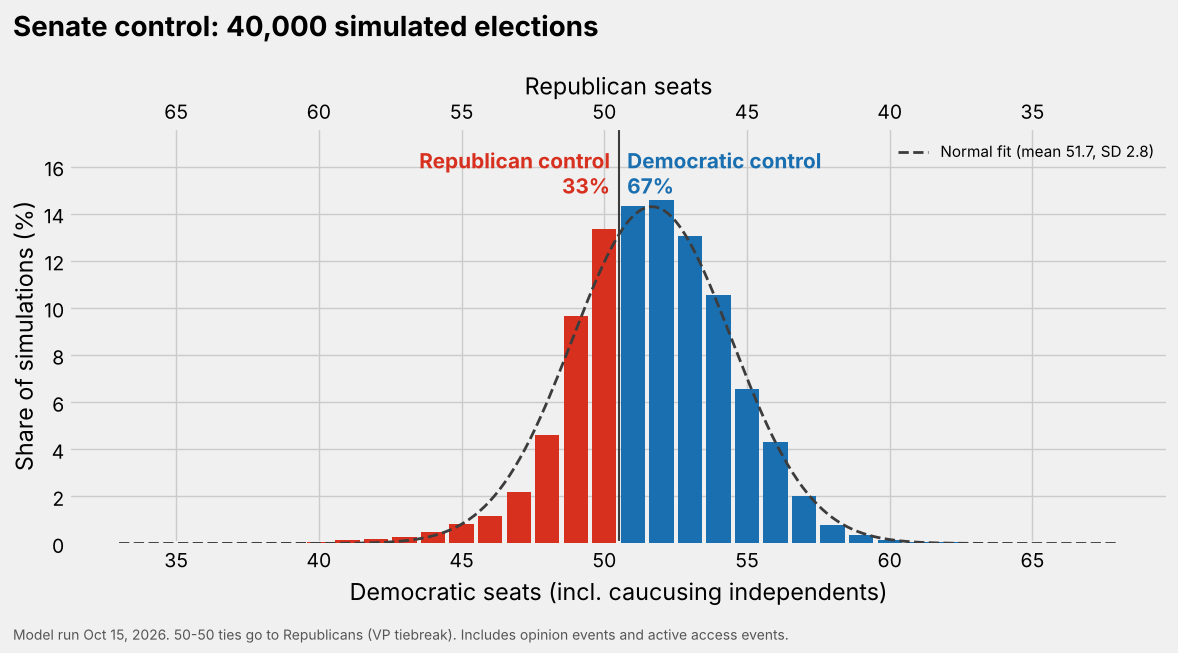

In [30]:
DEM_BLUE, REP_RED = "#1A6FB0", "#D7301F"


def plot_seat_distribution(d_seats, path=None, title=None):
    seats, counts = np.unique(d_seats, return_counts=True)
    pct = 100 * counts / len(d_seats)
    p_dem = (d_seats >= D_SEATS_FOR_CONTROL).mean()
    mu, sd = d_seats.mean(), d_seats.std()

    with plt.style.context("fivethirtyeight"):
        fig, ax = plt.subplots(figsize=(12, 6.5))
        colors = np.where(seats >= D_SEATS_FOR_CONTROL, DEM_BLUE, REP_RED)
        ax.bar(seats, pct, width=0.85, color=colors, zorder=3)
        x = np.linspace(seats.min() - 2, seats.max() + 2, 400)
        ax.plot(x, 100 * norm.pdf(x, mu, sd), color="#3C3C3C", lw=2, ls="--",
                zorder=4, label=f"Normal fit (mean {mu:.1f}, SD {sd:.1f})")
        ax.axvline(D_SEATS_FOR_CONTROL - 0.5, color="#3C3C3C", lw=1.5, zorder=2)
        top = pct.max() * 1.15
        ax.text(D_SEATS_FOR_CONTROL - 0.8, top, f"Republican control\n{1 - p_dem:.0%}",
                ha="right", va="top", color=REP_RED, fontsize=15, fontweight="bold")
        ax.text(D_SEATS_FOR_CONTROL - 0.2, top, f"Democratic control\n{p_dem:.0%}",
                ha="left", va="top", color=DEM_BLUE, fontsize=15, fontweight="bold")
        ax.set_ylim(0, top * 1.05)
        ax.set_xlabel("Democratic seats (incl. caucusing independents)")
        ax.set_ylabel("Share of simulations (%)")
        sec = ax.secondary_xaxis("top", functions=(lambda v: 100 - v, lambda v: 100 - v))
        sec.set_xlabel("Republican seats")
        ax.legend(loc="upper right", frameon=False, fontsize=11)
        fig.suptitle(title or f"Senate control: {len(d_seats):,} simulated elections",
                     x=0.02, ha="left", fontsize=20, fontweight="bold")
        fig.text(0.02, 0.01, f"Model run {TODAY:%b %d, %Y}. 50-50 ties go to Republicans "
                 f"(VP tiebreak). Includes opinion events and active access events.", fontsize=10, color="#555555")
        fig.tight_layout(rect=(0, 0.03, 1, 1))
        if path:
            fig.savefig(path, dpi=200, bbox_inches="tight")
        plt.show()
    return fig


plot_seat_distribution(d_seats, OUT_DIR / "seat_distribution.png");

In [31]:
def race_rating(p_dem, state):
    opp = "Ind" if state in INDEPENDENT_CAUCUS_PROB_D else "D"
    fav, top = (opp, p_dem) if p_dem >= 0.5 else ("R", 1 - p_dem)
    if top < 0.60:
        return "Toss-up"
    level = "Lean" if top < 0.70 else "Likely" if top < 0.85 else "Safe"
    # PLEASE TWEAK THIS PART - I DONT KNOW IF WE ALL AGREE ON LEAN/LIKELY/SAFE!
    return f"{level} {fav}"


win_table = pd.DataFrame({
    "Incumbent party": races["incumbent_party"],
    "Projected margin": sims.mean().apply(margin_label),
    "P(Dem win)": races["p_dem_national_sim"],
    "P(Rep win)": 1 - races["p_dem_national_sim"],
})
win_table["Rating"] = [race_rating(p, st) for st, p in win_table["P(Dem win)"].items()]
win_table.index = [f"{st} (Ind)" if st in INDEPENDENT_CAUCUS_PROB_D else st for st in win_table.index]
win_table.index.name = "State"
win_table = win_table.sort_values("P(Dem win)", ascending=False)
win_table.to_csv(OUT_DIR / "state_win_probabilities.csv")

display_table = win_table.copy()
for col in ["P(Dem win)", "P(Rep win)"]:
    display_table[col] = display_table[col].map("{:.0%}".format)
display_table

,Incumbent party,Projected margin,P(Dem win),P(Rep win),Rating
State,,,,,
Massachusetts,D,D+29.8,100%,0%,Safe D
Rhode Island,D,D+28.0,100%,0%,Safe D
Delaware,D,D+24.0,100%,0%,Safe D
Oregon,D,D+24.1,100%,0%,Safe D
Illinois,D,D+17.3,100%,0%,Safe D
Colorado,D,D+20.1,99%,1%,Safe D
New Jersey,D,D+16.0,98%,2%,Safe D
New Mexico,D,D+11.1,98%,2%,Safe D
North Carolina,R,D+9.0,98%,2%,Safe D


## Step 8: Access scenarios

Each access row in `Events.xlsx` gets run on top of the opinion events, one at a time, then all together. Same random draws every time, so the differences are the row's doing. The real changes (active rows) are also in the main forecast; the scenarios are not.

How the research translates into parameters:

* Polling place moves: Clinton et al. (2021) find that in North Carolina, early voting almost fully offsets the Election Day drop after a polling place change. Brady and McNulty (2011) and Cantoni (2020) find net losses when travel and search costs rise. So deterrence is low where vote centers and early voting exist (Tarrant County) and higher where they don't.
* Evictions: Slee and Desmond (2023) find a 1-point rise in a neighborhood's eviction rate cut 2016 turnout by 0.46 points (OLS) to 2.73 points (instrumental variables). Evictions already in place are baked into the baseline, and 2025 filings at tracked sites ran 3.2% below the 2023-24 average, so only local increases (Travis County, Texas) are worth a row.
* Digital suppression: Kim et al. (2026) find exposure to suppression ads in 2016 cut turnout 1.9 points on average, about 5.8 points in battleground states, and about 17 points among targeted non-White voters in minority counties of battleground states (wide intervals). No 2026 exposure data exist, so this stays a scenario. Rigorous designs find small average turnout effects for strict ID laws (Cantoni & Pons, 2021). Physical costs, like a longer trip to the polling place (Brady & McNulty, 2011; Cantoni, 2020) or fewer early voting days (Kaplan & Yuan, 2020), show clearer turnout effects. Partisan effects tend to be smaller than the turnout effects, since burdens hit voters in both parties (Thompson et al., 2020, find the same on the expansion side). Backlash can offset some of the loss (Valentino & Neuner, 2017). In administrative burden terms (Herd & Moynihan, 2018), the formula's inputs are who carries the compliance cost (`affected_share`, `lean_gap`) and how much of it converts into a lost ballot (`deterrence`).

In [32]:
def summarize_run(s):
    seats = s["d_seats"]
    return pd.Series({
        "P(D control)": (seats >= D_SEATS_FOR_CONTROL).mean(),
        "Mean D seats": seats.mean(),
        "D seats, 10th pct": np.percentile(seats, 10),
        "D seats, 90th pct": np.percentile(seats, 90),
    })


runs = {"No events (starter model)": sim_base,
        "Opinion events only": simulate(races, draws, exposure, opinion_post["post_sd"]),
        "Main forecast (opinion + active access rows)": sim}
for eid, rows in access.groupby("event_id", sort=False):
    runs[f"Opinion + {eid}"] = simulate(races, draws, exposure, opinion_post["post_sd"], rows)
runs["Opinion + every access scenario"] = simulate(races, draws, exposure, opinion_post["post_sd"], access)

scenario_table = pd.DataFrame({k: summarize_run(v) for k, v in runs.items()}).T
base_p = scenario_table.loc["Opinion events only", "P(D control)"]
scenario_table["Change in P(D control) vs opinion only (pts)"] = 100 * (scenario_table["P(D control)"] - base_p)
scenario_table.to_csv(OUT_DIR / "scenario_comparison.csv")

shown = scenario_table.copy()
shown["P(D control)"] = shown["P(D control)"].map("{:.1%}".format)
print(access.set_index("event_id")[["name", "active"]].to_string(), "\n")
shown.round(2)

                                                                                                                     name  active
event_id                                                                                                                         
OH-GRACE                      Ohio S.B. 293: domestic mail ballots must arrive by Election Day (4-day grace period ended)    True
TX-TARRANT                                       Tarrant County, TX cuts Election Day sites from 316 (2022) to 224 (2026)    True
KS-GRACE                       Kansas S.B. 4: ends the 3-day mail ballot grace period (blocked by a temporary injunction)    True
IA-OATH                                        Iowa H.F. 2501: ends identity attestation (vouching) for voters without ID    True
NH-POC      New Hampshire H.B. 1569: documentary proof of citizenship to register (struck down 5/28/2026, appeal pending)    True
DIG-BG        SCENARIO: targeted digital voter suppression ads in the 13 battlegrounds, at

,P(D control),Mean D seats,"D seats, 10th pct","D seats, 90th pct",Change in P(D control) vs opinion only (pts)
No events (starter model),66.9%,51.66,48.0,55.0,-0.09
Opinion events only,67.0%,51.67,48.0,55.0,0.00
Main forecast (opinion + active access rows),66.9%,51.67,48.0,55.0,-0.05
Opinion + OH-GRACE,66.9%,51.67,48.0,55.0,-0.04
Opinion + TX-TARRANT,66.9%,51.67,48.0,55.0,-0.01
Opinion + KS-GRACE,67.0%,51.67,48.0,55.0,-0.00
Opinion + IA-OATH,67.0%,51.67,48.0,55.0,0.00
Opinion + NH-POC,67.0%,51.67,48.0,55.0,0.00
Opinion + DIG-BG,66.6%,51.65,48.0,55.0,-0.36
Opinion + EV-TRAVIS,66.9%,51.67,48.0,55.0,-0.09


Where each scenario lands, limited to races that are competitive in the opinion-only run (P(D) between 10% and 90%):

In [33]:
competitive = runs["Opinion events only"]["p_dem"].between(0.10, 0.90)
rows = []
for eid in access["event_id"].unique():
    s = runs[f"Opinion + {eid}"]
    hit = s["access_shift"].abs().mean() > 1e-9
    for st in s["p_dem"].index[hit & competitive]:
        sh = s["access_shift"][st]
        rows.append({"scenario": eid, "race": st,
                     "mean shift": sh.mean(),
                     "5th pct": sh.quantile(0.05), "95th pct": sh.quantile(0.95),
                     "P(D) opinion only": runs["Opinion events only"]["p_dem"][st],
                     "P(D) scenario": s["p_dem"][st]})
pd.DataFrame(rows).round(2)

,scenario,race,mean shift,5th pct,95th pct,P(D) opinion only,P(D) scenario
0,OH-GRACE,Ohio,-0.02,-0.06,-0.00,0.68,0.68
1,TX-TARRANT,Texas,-0.00,-0.01,0.00,0.60,0.60
2,KS-GRACE,Kansas,-0.00,-0.02,0.00,0.31,0.31
3,IA-OATH,Iowa,-0.00,-0.01,0.00,0.45,0.45
4,DIG-BG,Alaska,-0.03,-0.14,-0.00,0.54,0.54
5,DIG-BG,Iowa,-0.03,-0.14,-0.00,0.45,0.44
6,DIG-BG,Kansas,-0.03,-0.14,-0.00,0.31,0.31
7,DIG-BG,Michigan,-0.03,-0.14,-0.00,0.88,0.88
8,DIG-BG,Nebraska,-0.03,-0.14,-0.00,0.12,0.12
9,DIG-BG,Ohio,-0.03,-0.14,-0.00,0.68,0.68


### Stress test: how big would an access shock have to be?

Instead of guessing parameters, sweep them. This runs a nationwide shock where the voters who lose their ballots are 20 points more Democratic than their state (blue line), or 20 points more Republican (red line), and raises the share of the electorate lost from 0 to 4%. It's a dose-response curve for Senate control.

The robustness table below it turns the formula around: for each competitive race, what share of the electorate would have to lose their ballots (with lost voters 20 points more favorable to the current leader) to erase the projected margin. It's a quick way to see which races sit inside the range plausible access effects can reach, and which don't.

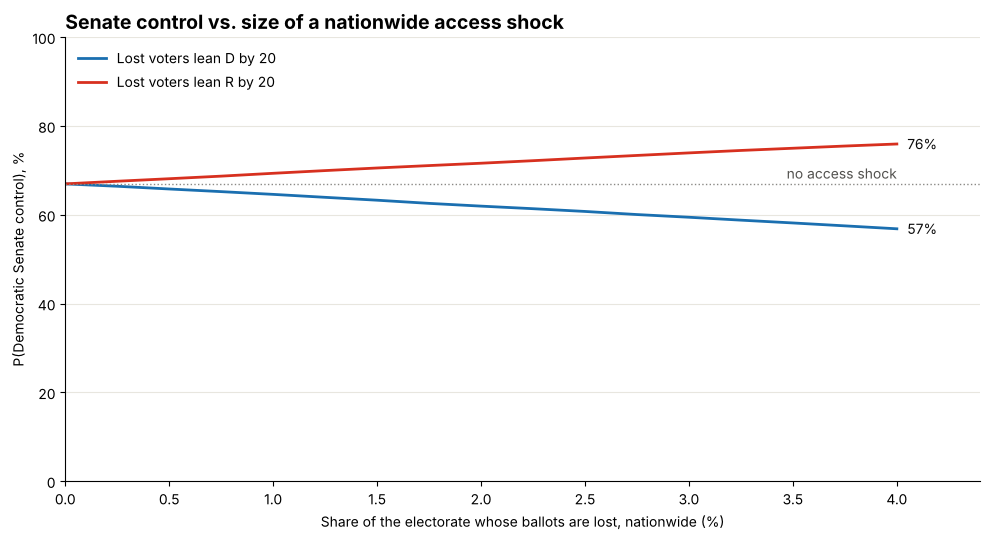

In [34]:
STRESS_AFFECTED_SHARE = 0.10   # the swept "lost share" is reached by raising deterrence within this group
STRESS_GAP = 20                # lost voters' lean relative to their state (margin points)
lost_grid = np.linspace(0, 0.04, 17)


def stress_rows(lost, gap):
    return pd.DataFrame([dict(event_id="STRESS", scope="national", affected_share=STRESS_AFFECTED_SHARE,
                              lean_gap=gap, lean_gap_sd=0, deterrence_mean=lost / STRESS_AFFECTED_SHARE,
                              deterrence_sd=0, countermobilization_mean=0, countermobilization_sd=0,
                              in_polls_share=0)])


sweep = pd.DataFrame({
    gap: [(simulate(races, draws, exposure, opinion_post["post_sd"], stress_rows(L, gap))["d_seats"]
           >= D_SEATS_FOR_CONTROL).mean() for L in lost_grid]
    for gap in (STRESS_GAP, -STRESS_GAP)
}, index=lost_grid)
sweep.to_csv(OUT_DIR / "access_stress_test.csv", index_label="share_of_electorate_lost")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(100 * lost_grid, 100 * sweep[STRESS_GAP], color=DEM_BLUE, lw=2,
        label=f"Lost voters lean D by {STRESS_GAP}")
ax.plot(100 * lost_grid, 100 * sweep[-STRESS_GAP], color=REP_RED, lw=2,
        label=f"Lost voters lean R by {STRESS_GAP}")
ax.axhline(100 * base_p, color="#8a8985", lw=1, ls=":")
ax.text(100 * lost_grid[-1], 100 * base_p + 1.2, "no access shock", ha="right", color="#52514e", fontsize=10)
for gap, color in [(STRESS_GAP, DEM_BLUE), (-STRESS_GAP, REP_RED)]:
    ax.text(100 * lost_grid[-1] + 0.05, 100 * sweep[gap].iloc[-1], f"{sweep[gap].iloc[-1]:.0%}",
            va="center", color="#0b0b0b", fontsize=10)
ax.set_xlabel("Share of the electorate whose ballots are lost, nationwide (%)")
ax.set_ylabel("P(Democratic Senate control), %")
ax.set_ylim(0, 100)
ax.set_xlim(0, 100 * lost_grid[-1] + 0.4)
ax.grid(axis="y", color="#e8e6df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Senate control vs. size of a nationwide access shock", loc="left", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "access_stress_test.png", dpi=200, bbox_inches="tight")
plt.show()

In [35]:
main_med = sims.median()
robust = pd.DataFrame({
    "median margin": main_med,
    "P(D)": races["p_dem_national_sim"],
})
robust = robust[robust["P(D)"].between(0.10, 0.90)].copy()
# Share lost L that erases margin M when lost voters favor the leader by STRESS_GAP: L = |M| / (gap + |M|)
robust["share of electorate lost to erase margin"] = robust["median margin"].abs() / (STRESS_GAP + robust["median margin"].abs())
shown = robust.sort_values("share of electorate lost to erase margin").copy()
shown["share of electorate lost to erase margin"] = shown["share of electorate lost to erase margin"].map("{:.1%}".format)
shown.round(2)

,median margin,P(D),share of electorate lost to erase margin
Alaska,0.42,0.54,2.1%
Iowa,-0.50,0.45,2.5%
Texas,0.92,0.60,4.4%
Ohio,1.84,0.68,8.4%
Kansas,-1.92,0.31,8.8%
South Carolina,-4.11,0.17,17.0%
Florida,-4.49,0.13,18.3%
Michigan,4.58,0.88,18.6%
Nebraska,-5.10,0.12,20.3%


## Step 9: Redrawn maps go to a House seats module

A Senate race is statewide. Every voter in the state is in the same "district," so redrawing House lines can't change a Senate margin. The code enforces that: map events add nothing to any Senate race. Any indirect path (a newly competitive House race pulling turnout or money into a state) would be an *opinion* or *access* event and belongs in those sheets.

What a map changes is the translation of votes into seats. The standard way to see that is a seats-votes curve: give each district its lean, add a national swing and district noise, and count seats (Gelman & King, 1994). This module does that for the old and new plan, using the same national draw as the Senate simulations.

The example state is **toy data**: 12 districts, statewide lean R+3. The old plan is mixed. The new plan packs Democrats into two very blue districts and spreads Republicans thin across ten R+6 to R+11 seats. Thin margins are efficient in a neutral year and fragile in a wave year. When a gerrymander backfires that way, it's a dummymander (Grofman & Brunell, 2005). The chart shows where that crossover would happen.

To use real maps, replace the `Map_Districts` rows with each district's partisan lean under the old and new plans (for example, presidential vote recomputed on the new lines).

### ⚙️ Tuning knobs: House module

In [36]:
HOUSE_DISTRICT_SD = 5.0     # district noise in margin points (candidates, new-district uncertainty)
# National swing in the House uses the same national draw as the Senate, at the Senate's national scale
HOUSE_NATIONAL_SD = np.sqrt(CORR_NATIONAL) * races["post_sd"].median()

Map events change Senate margins by: 0.0 points in every race (statewide races don't use district lines)



HYPOTHETICAL mid-decade redraw (TOY DATA) (Example State, 12 districts)
  statewide lean: old -3.0, new -3.0


,old plan,new plan,new - old
mean D seats,6.41,2.92,-3.49
10th pct,5.00,2.00,-3.00
90th pct,8.00,5.00,-3.00


  P(new plan gives D fewer seats than old plan) = 99%


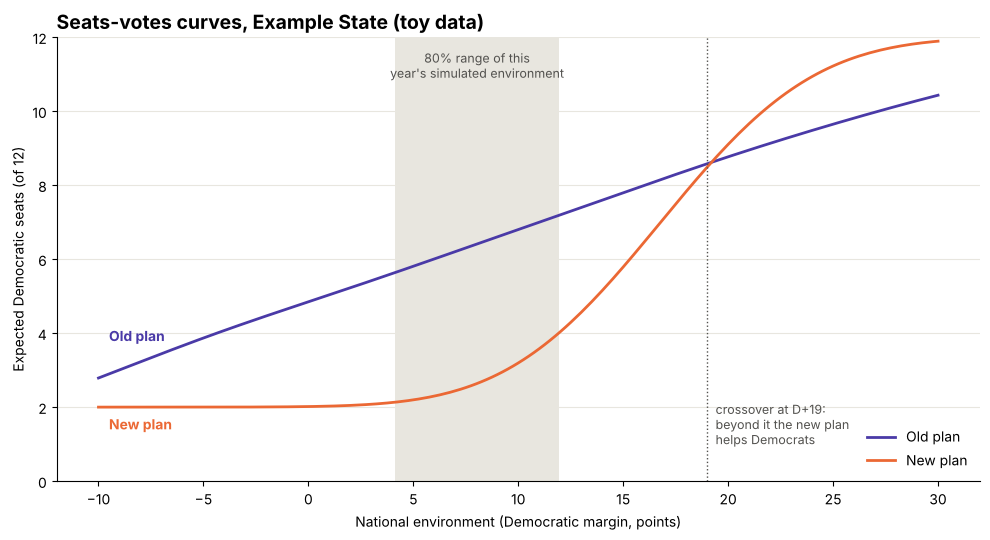

,national env (D margin),old plan,new plan,new - old
0,0,4.85,2.02,-2.83
1,5,5.81,2.20,-3.61
2,10,6.80,3.19,-3.61
3,15,7.80,5.79,-2.01
4,20,8.77,9.10,0.34
5,25,9.65,11.22,1.57


In [37]:
# Map events never touch Senate margins
print("Map events change Senate margins by: 0.0 points in every race (statewide races don't use district lines)")


def house_env_draws(draws):
    # National environment for House races in each simulation: same national draw as the Senate,
    # plus national opinion-event uncertainty and any active national access shock
    e = env_events + HOUSE_NATIONAL_SD * draws["eta"]
    for eid, ev in opinion[opinion["national"]].iterrows():
        e = e + opinion_post.loc[eid, "post_sd"] * draws["opinion"][eid] * env_exposure(ev)
    e = e + access_shift(["__district__"], access[access["active"]], draws)[:, 0]
    return e


def house_seats(pvi, env_draws, seed):
    noise = np.random.default_rng(seed).standard_normal((len(env_draws), len(pvi)))
    return ((2 * pvi[None, :] + env_draws[:, None] + HOUSE_DISTRICT_SD * noise) > 0).sum(axis=1)


def expected_seats(pvi, env_grid):
    return norm.cdf((2 * pvi[None, :] + env_grid[:, None]) / HOUSE_DISTRICT_SD).sum(axis=1)


env_h = house_env_draws(draws)
env_grid = np.linspace(-10, 30, 161)
OLD_COLOR, NEW_COLOR = "#4a3aa7", "#eb6834"

for _, mev in maps.iterrows():
    dist = map_districts[map_districts["map_event"] == mev["event_id"]]
    pvi_old = dist.loc[dist["plan"] == mev["plan_old"], "pvi"].to_numpy(float)
    pvi_new = dist.loc[dist["plan"] == mev["plan_new"], "pvi"].to_numpy(float)
    n_seats = len(pvi_old)
    seats_old = house_seats(pvi_old, env_h, SEED + 1)
    seats_new = house_seats(pvi_new, env_h, SEED + 1)

    print(f"\n{mev['name']} ({mev['state']}, {n_seats} districts)")
    print(f"  statewide lean: old {pvi_old.mean():+.1f}, new {pvi_new.mean():+.1f}")
    summary = pd.DataFrame({
        "old plan": [seats_old.mean(), np.percentile(seats_old, 10), np.percentile(seats_old, 90)],
        "new plan": [seats_new.mean(), np.percentile(seats_new, 10), np.percentile(seats_new, 90)],
    }, index=["mean D seats", "10th pct", "90th pct"])
    summary["new - old"] = summary["new plan"] - summary["old plan"]
    display(summary.round(2))
    print(f"  P(new plan gives D fewer seats than old plan) = {(seats_new < seats_old).mean():.0%}")

    curve_old, curve_new = expected_seats(pvi_old, env_grid), expected_seats(pvi_new, env_grid)
    diff = curve_new - curve_old
    cross = env_grid[np.where(np.diff(np.sign(diff)) != 0)[0]]
    lo, hi = np.percentile(env_h, [10, 90])

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.axvspan(lo, hi, color="#e8e6df", lw=0)
    ax.text((lo + hi) / 2, n_seats * 0.97, "80% range of this\nyear's simulated environment",
            ha="center", va="top", fontsize=9, color="#52514e")
    ax.plot(env_grid, curve_old, color=OLD_COLOR, lw=2, label="Old plan")
    ax.plot(env_grid, curve_new, color=NEW_COLOR, lw=2, label="New plan")
    ax.text(env_grid[0] + 0.5, curve_old[0] + 1.0, "Old plan", color=OLD_COLOR, fontsize=10, fontweight="bold")
    ax.text(env_grid[0] + 0.5, curve_new[0] - 0.6, "New plan", color=NEW_COLOR, fontsize=10, fontweight="bold")
    for c in cross[cross > 0]:
        ax.axvline(c, color="#52514e", lw=1, ls=":")
        ax.text(c + 0.4, 1.0, f"crossover at D+{c:.0f}:\nbeyond it the new plan\nhelps Democrats",
                fontsize=9, color="#52514e")
    ax.set_xlabel("National environment (Democratic margin, points)")
    ax.set_ylabel(f"Expected Democratic seats (of {n_seats})")
    ax.set_ylim(0, n_seats)
    ax.grid(axis="y", color="#e8e6df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
    ax.set_title(f"Seats-votes curves, {mev['state']} (toy data)", loc="left", fontsize=14, fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"house_map_{mev['event_id']}.png", dpi=200, bbox_inches="tight")
    plt.show()

    gap_tbl = pd.DataFrame({"national env (D margin)": [0, 5, 10, 15, 20, 25]})
    g = gap_tbl["national env (D margin)"].to_numpy(float)
    gap_tbl["old plan"] = expected_seats(pvi_old, g)
    gap_tbl["new plan"] = expected_seats(pvi_new, g)
    gap_tbl["new - old"] = gap_tbl["new plan"] - gap_tbl["old plan"]
    display(gap_tbl.round(2))

## Step 10: Save outputs

In [38]:
out.to_csv(OUT_DIR / "race_probabilities.csv")
decomp.to_csv(OUT_DIR / "event_decomposition.csv")
opinion_post.to_csv(OUT_DIR / "opinion_event_estimates.csv")
pd.Series(d_seats).value_counts().sort_index() \
    .rename("n_sims").to_csv(OUT_DIR / "seat_distribution.csv", index_label="dem_seats")
print("Saved to", OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print("  ", f.name)

Saved to /home/claude/deliverables/senate-forecast-2026/outputs/notebook
   access_stress_test.csv
   access_stress_test.png
   battlegrounds.csv
   event_decomposition.csv
   house_map_MAP1.png
   opinion_event_estimates.csv
   race_probabilities.csv
   scenario_comparison.csv
   seat_distribution.csv
   seat_distribution.png
   state_win_probabilities.csv


## What this layer can't do

* **Opinion events are hard to see in a week of polls.** The event study needs same-pollster pairs, and most events get two or three. Expect the prior to do most of the work, and treat the prior as a claim you're making. Overlapping events can't be separated.
* **Access parameters come from outside the data.** No Senate poll measures deterrence. The priors come from the causal literature on specific laws, and effects vary a lot by law, place, and implementation. Scenarios and the stress test are the honest use; a single point estimate isn't.
* **Likely voter screens partly adapt.** If people know a rule will block them, some will tell pollsters they won't vote. `in_polls_share` handles that, and 0 is the right setting only for changes close to the election.
* **Only changes count.** Laws already in force are baked into the partisan lean and the polls. Add a row only for something new since then.
* **Counting and certification fights are outside a vote-share model.** The model forecasts the counted margin. Disputes after Election Day need a separate layer.
* **Polling place data are incomplete.** Tarrant County is the only battleground-state cut documented here. County election boards publish site lists; comparing 2022 and 2026 lists is the way to find the rest.
* **Several 2025-26 laws are not modeled** because no count of affected voters was found: SAVE-database citizenship checks (Iowa, Kansas), Kansas H.B. 2437 and S.B. 244, Nebraska L.B. 1075, New Hampshire H.B. 323 (student IDs), and Texas H.B. 521. North Carolina's H.B. 958 was vetoed but could still be overridden.
* **The House module runs on toy data** until real district leans go in.

## References

Brady, H. E., & McNulty, J. E. (2011). Turning out to vote: The costs of finding and getting to the polling place. *American Political Science Review, 105*(1), 115–134. https://doi.org/10.1017/S0003055410000596

Cantoni, E. (2020). A precinct too far: Turnout and voting costs. *American Economic Journal: Applied Economics, 12*(1), 61–85. https://doi.org/10.1257/app.20180306

Cantoni, E., & Pons, V. (2021). Strict ID laws don't stop voters: Evidence from a U.S. nationwide panel, 2008–2018. *The Quarterly Journal of Economics, 136*(4), 2615–2660. https://doi.org/10.1093/qje/qjab019

Clinton, J. D., Eubank, N., Fresh, A., & Shepherd, M. E. (2021). Polling place changes and political participation: Evidence from North Carolina presidential elections, 2008–2016. *Political Science Research and Methods, 9*(4), 800–817.

Gelman, A., & King, G. (1994). A unified method of evaluating electoral systems and redistricting plans. *American Journal of Political Science, 38*(2), 514–554.

Gerber, A. S., Gimpel, J. G., Green, D. P., & Shaw, D. R. (2011). How large and long-lasting are the persuasive effects of televised campaign ads? Results from a randomized field experiment. *American Political Science Review, 105*(1), 135–150.

Grofman, B., & Brunell, T. L. (2005). The art of the dummymander: The impact of recent redistrictings on the partisan makeup of southern House seats. In P. F. Galderisi (Ed.), *Redistricting in the new millennium* (pp. 183–199). Lexington Books.

Herd, P., & Moynihan, D. P. (2018). *Administrative burden: Policymaking by other means*. Russell Sage Foundation.

Kaplan, E., & Yuan, H. (2020). Early voting laws, voter turnout, and partisan vote composition: Evidence from Ohio. *American Economic Journal: Applied Economics, 12*(1), 32–60. https://doi.org/10.1257/app.20180192

Kim, Y. M., Dahlke, R., Song, H., & Heinrich, R. (2026). Targeted digital voter suppression efforts likely decrease voter turnout. *Proceedings of the National Academy of Sciences, 123*(5), e2519944123. https://doi.org/10.1073/pnas.2519944123

Slee, G., & Desmond, M. (2023). Eviction and voter turnout: The political consequences of housing instability. *Politics & Society, 51*(1), 3–29. https://doi.org/10.1177/00323292211050716

Thompson, D. M., Wu, J. A., Yoder, J., & Hall, A. B. (2020). Universal vote-by-mail has no impact on partisan turnout or vote share. *Proceedings of the National Academy of Sciences, 117*(25), 14052–14056. https://doi.org/10.1073/pnas.2007249117

Valentino, N. A., & Neuner, F. G. (2017). Why the sky didn't fall: Mobilizing anger in reaction to voter ID laws. *Political Psychology, 38*(2), 331–350. https://doi.org/10.1111/pops.12332